In [1]:
# ============================================================
#  ORI 2026 — EKSPERIMENT 3: PREDVIĐANJE TRENDA kroz SMER PRINOSA
#  3-1 (a/b/c): Klasifikacija sign(ROC)  ← bazne feature-grupe
#  3-2 (a/b/c): Klasifikacija sign(ROC)  ← + ROC od feature-grupa
#  3-3 (a/b/c): Regresija  ROC(h)        ← + ROC + SMA od feature-grupa
# ============================================================

import pandas as pd
import numpy as np
import os
import glob
import warnings
import itertools
from math import sqrt

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
)

warnings.filterwarnings('ignore')

In [2]:

# ──────────────────────────────────────────────────────────────
#  0. UČITAVANJE PODATAKA  (isti loader kao u Exp1/Exp2)
# ──────────────────────────────────────────────────────────────

possible_dirs = [".", "data", "./data", "../data"]
INPUT_DIR = ".."
for dir_path in possible_dirs:
    if os.path.exists(dir_path):
        csv_files = glob.glob(os.path.join(dir_path, "*_Data.csv"))
        if csv_files and len(csv_files) >= 5:
            INPUT_DIR = dir_path
            break

print(f"✓ CSV fajlovi pronađeni u: {INPUT_DIR}")


✓ CSV fajlovi pronađeni u: data


In [3]:

def load_csv(path):
    df = pd.read_csv(path, encoding="utf-8-sig")
    df.columns = [c.strip().strip('"') for c in df.columns]
    return df


def clean_numeric_column(series):
    s = series.astype(str).str.replace(",", "", regex=False)
    s = s.str.replace("%", "", regex=False)

    def parse_suffix(val):
        if not isinstance(val, str):
            return np.nan if pd.isna(val) else float(val)
        val = val.strip()
        if val in ("", "nan", "None", "-"):
            return np.nan
        multiplier = 1
        if val.endswith("K"):
            multiplier, val = 1_000, val[:-1]
        elif val.endswith("M"):
            multiplier, val = 1_000_000, val[:-1]
        elif val.endswith("B"):
            multiplier, val = 1_000_000_000, val[:-1]
        try:
            return float(val) * multiplier
        except ValueError:
            return np.nan

    return s.apply(parse_suffix)


csv_files = sorted(glob.glob(os.path.join(INPUT_DIR, "*_Data.csv")))
print(f"Pronađeno {len(csv_files)} CSV fajlova:\n")

Pronađeno 6 CSV fajlova:



In [4]:

all_data = []
for path in csv_files:
    pair_name = os.path.basename(path).replace("_Data.csv", "")
    df_raw = load_csv(path)
    df_raw["Date"] = pd.to_datetime(df_raw["Date"], format="%m/%d/%Y", errors="coerce")
    numeric_cols = [c for c in ["Price", "Open", "High", "Low", "Change %"] if c in df_raw.columns]
    for col in numeric_cols:
        df_raw[col] = clean_numeric_column(df_raw[col])
    keep_cols = ["Date"] + numeric_cols
    df = df_raw[keep_cols].dropna(subset=["Date", "Price"])
    df["Pair"] = pair_name
    all_data.append(df)
    print(f"  ✓ {pair_name:10s}: {len(df)} redova")

  ✓ EURUSD    : 2610 redova
  ✓ USDCAD    : 2610 redova
  ✓ USDCHF    : 2610 redova
  ✓ USDCNY    : 2611 redova
  ✓ USDGBP    : 2610 redova
  ✓ USDJPY    : 2610 redova


In [5]:

# Ukloni USDCNY datume kojih nema u ostalim parovima
other_dates = set()
for df in all_data:
    if df["Pair"].iloc[0] != "USDCNY":
        other_dates.update(df["Date"])
for i, df in enumerate(all_data):
    if df["Pair"].iloc[0] == "USDCNY":
        before = len(df)
        all_data[i] = df[df["Date"].isin(other_dates)]
        removed = before - len(all_data[i])
        if removed > 0:
            print(f"\n  ⚠ USDCNY: uklonjeno {removed} redova sa nepostojećim datumima ({before} → {len(all_data[i])})")

currency_all = pd.concat(all_data, ignore_index=True)
currency_all = currency_all.sort_values(["Pair", "Date"]).reset_index(drop=True)
print(f"\n✓ Ukupno: {len(currency_all)} redova za {currency_all['Pair'].nunique()} parova")


  ⚠ USDCNY: uklonjeno 1 redova sa nepostojećim datumima (2611 → 2610)

✓ Ukupno: 15660 redova za 6 parova


In [6]:

# ──────────────────────────────────────────────────────────────
#  1. INDIKATORI  (isti kao u Exp1/Exp2)
# ──────────────────────────────────────────────────────────────

from ta.trend import SMAIndicator, EMAIndicator, MACD, CCIIndicator, PSARIndicator
from ta.momentum import ROCIndicator, RSIIndicator
from ta.volatility import AverageTrueRange
from stockstats import StockDataFrame

INDICATOR_COLS = [
    "SMA_14", "EMA_14", "ROC_14", "RSI_14",
    "MACD", "MACD_Signal", "MACD_Hist",
    "STD_14", "ATR_14",
    "KAMA_14", "SAR", "CCI_14", "CMO_14",
]


def calculate_indicators(pair_df):
    close = pair_df["Price"]
    high  = pair_df["High"] if "High" in pair_df.columns else close
    low   = pair_df["Low"]  if "Low"  in pair_df.columns else close

    out = pd.DataFrame(index=pair_df.index)
    out["SMA_14"]      = SMAIndicator(close=close, window=14).sma_indicator()
    out["EMA_14"]      = EMAIndicator(close=close, window=14).ema_indicator()
    out["ROC_14"]      = ROCIndicator(close=close, window=14).roc()
    out["RSI_14"]      = RSIIndicator(close=close, window=14).rsi()
    macd               = MACD(close=close, window_slow=26, window_fast=12, window_sign=9)
    out["MACD"]        = macd.macd()
    out["MACD_Signal"] = macd.macd_signal()
    out["MACD_Hist"]   = macd.macd_diff()
    out["STD_14"]      = close.rolling(14).std()
    out["ATR_14"]      = AverageTrueRange(high=high, low=low, close=close, window=14).average_true_range()
    out["CCI_14"]      = CCIIndicator(high=high, low=low, close=close, window=14).cci()
    psar               = PSARIndicator(high=high, low=low, close=close, step=0.025, max_step=0.25)
    out["SAR"]         = psar.psar()
    stock = StockDataFrame.retype(pd.DataFrame({
        "close": close.values, "high": high.values, "low": low.values,
        "open": close.values,  "volume": np.ones(len(close)),
    }, index=pair_df.index))
    out["KAMA_14"] = stock["kama_14"]
    out["CMO_14"]  = stock["cmo_14"]
    return out



In [7]:

all_features = []
for pair_name in currency_all["Pair"].unique():
    pair_data  = currency_all[currency_all["Pair"] == pair_name].sort_values("Date").reset_index(drop=True)
    indicators = calculate_indicators(pair_data)
    indicators["Date"]  = pair_data["Date"].values
    indicators["Price"] = pair_data["Price"].values
    indicators["Pair"]  = pair_name
    all_features.append(indicators)
    print(f"  ✓ {pair_name}: {len(indicators)} redova")

features = pd.concat(all_features, ignore_index=True)
features  = features[["Pair", "Date", "Price"] + INDICATOR_COLS]
print(f"\n✓ Shape: {features.shape}")

  ✓ USDJPY: 2610 redova

✓ Shape: (15660, 16)


In [8]:

N_LAGS            = 5
N_LAGS_INDICATORS = 2
TEST_SIZE         = 0.2
ROC_WINDOW        = 14   # prozor za ROC/SMA transformacije ulaznih feature-a
SMA_WINDOW        = 14

MLP_PARAMS_CLF = {
    'hidden_layer_sizes': (64, 32, 16),
    'activation': 'relu',
    'solver': 'adam',
    'learning_rate_init': 0.001,
    'max_iter': 2000,
    'early_stopping': True,
    'validation_fraction': 0.1,
    'n_iter_no_change': 25,
    'alpha': 0.001,
    'random_state': 42,
    'verbose': 0,
}

MLP_PARAMS_REG = {
    'hidden_layer_sizes': (64, 32, 16),
    'activation': 'relu',
    'solver': 'adam',
    'learning_rate_init': 0.001,
    'max_iter': 2000,
    'early_stopping': True,
    'validation_fraction': 0.1,
    'n_iter_no_change': 25,
    'alpha': 0.001,
    'random_state': 42,
    'verbose': 0,
}


def add_roc(df, cols, n):
    """ROC(n) za svaku kolonu u cols: (x[t] - x[t-n]) / x[t-n] * 100.
    Inf vrednosti se sanitizuju u NaN."""
    out = pd.DataFrame(index=df.index)
    for c in cols:
        roc = df[c].pct_change(n) * 100
        roc = roc.replace([np.inf, -np.inf], np.nan)
        out[f"ROC{n}_{c}"] = roc
    return out


def add_sma(df, cols, n):
    """SMA(n) za svaku kolonu u cols."""
    out = pd.DataFrame(index=df.index)
    for c in cols:
        out[f"SMA{n}_{c}"] = df[c].rolling(n).mean()
    return out


def add_sign_roc_targets(df, horizons):
    """Ciljna promenljiva za klasifikaciju: sign(ROC(h)) ∈ {-1, 0, +1}
    Koristimo samo -1/+1 — nule proglašavamo +1 (rast) radi stabilnosti."""
    out = pd.DataFrame(index=df.index)
    for h in horizons:
        roc_h = df["Price"].pct_change(h).shift(-h) * 100   # buduci ROC
        roc_h = roc_h.replace([np.inf, -np.inf], np.nan)
        sign  = np.sign(roc_h)
        sign  = sign.replace(0, 1)   # neutralno → rast
        out[f"SignROC_{h}"] = sign
    return out


def add_roc_targets(df, horizons):
    """Ciljna promenljiva za regresiju: ROC(h) (buduci prinos)."""
    out = pd.DataFrame(index=df.index)
    for h in horizons:
        roc_h = df["Price"].pct_change(h).shift(-h) * 100
        roc_h = roc_h.replace([np.inf, -np.inf], np.nan)
        out[f"ROC_{h}"] = roc_h
    return out


def mape_safe(y_true, y_pred, eps=1e-9):
    mask = np.abs(y_true) > eps
    if mask.sum() == 0:
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

In [9]:


def run_classification(X, y, test_size=TEST_SIZE, dates=None, scaler_type='standard'):
    """MLP klasifikator. Vraća rečnik sa metrikama i predikcijama."""
    split_idx = int(len(X) * (1 - test_size))
    X_train, X_test = X[:split_idx], X[split_idx:]
    y_train, y_test = y[:split_idx], y[split_idx:]

    if len(X_train) < 30 or len(X_test) < 10:
        return None
    if len(np.unique(y_train)) < 2:
        return None

    Scaler      = RobustScaler if scaler_type == 'robust' else StandardScaler
    scaler      = Scaler()
    X_train_s   = scaler.fit_transform(X_train)
    X_test_s    = scaler.transform(X_test)

    model = MLPClassifier(**MLP_PARAMS_CLF)
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)

    acc   = accuracy_score(y_test, y_pred) * 100
    prec  = precision_score(y_test, y_pred, average='weighted', zero_division=0) * 100
    rec   = recall_score(y_test, y_pred, average='weighted', zero_division=0) * 100
    f1    = f1_score(y_test, y_pred, average='weighted', zero_division=0) * 100
    converged = model.n_iter_ < MLP_PARAMS_CLF['max_iter']

    test_dates = dates[split_idx:] if dates is not None else None

    return {
        "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1,
        "Train_Size": len(X_train), "Test_Size": len(X_test),
        "y_test": y_test, "y_pred": y_pred, "test_dates": test_dates,
        "n_iter": model.n_iter_, "converged": converged, "n_features": X.shape[1],
    }


In [10]:

def run_regression(X, y, test_size=TEST_SIZE, dates=None, scaler_type='standard'):
    """MLP regresor (isti kao u Exp1/Exp2). Vraća rečnik sa metrikama i predikcijama."""
    split_idx = int(len(X) * (1 - test_size))
    X_train, X_test = X[:split_idx], X[split_idx:]
    y_train, y_test = y[:split_idx], y[split_idx:]

    if len(X_train) < 30 or len(X_test) < 10:
        return None

    Scaler      = RobustScaler if scaler_type == 'robust' else StandardScaler
    scaler      = Scaler()
    X_train_s   = scaler.fit_transform(X_train)
    X_test_s    = scaler.transform(X_test)

    model = MLPRegressor(**MLP_PARAMS_REG)
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)

    mae  = mean_absolute_error(y_test, y_pred)
    rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
    r2   = r2_score(y_test, y_pred)
    mape = mape_safe(y_test, y_pred)
    converged  = model.n_iter_ < MLP_PARAMS_REG['max_iter']
    test_dates = dates[split_idx:] if dates is not None else None

    return {
        "MAE": mae, "RMSE": rmse, "R2": r2, "MAPE": mape,
        "Train_Size": len(X_train), "Test_Size": len(X_test),
        "y_test": y_test, "y_pred": y_pred, "test_dates": test_dates,
        "n_iter": model.n_iter_, "converged": converged, "n_features": X.shape[1],
    }

In [11]:


def plot_confusion_matrix(cm, ax, title, classes=["DOWN", "UP"]):
    """Normalizovana confusion matrix na datoj osi."""
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)
    ax.imshow(cm_norm, interpolation='nearest', cmap='Blues', vmin=0, vmax=1)
    ax.set_title(title, fontsize=8, pad=4)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(classes, fontsize=8)
    ax.set_yticklabels(classes, fontsize=8)
    ax.set_ylabel('Stvarno',    fontsize=7)
    ax.set_xlabel('Predviđeno', fontsize=7)
    for i, j in itertools.product(range(2), range(2)):
        ax.text(j, i, f"{cm[i,j]}\n({cm_norm[i,j]:.0%})",
                ha='center', va='center', fontsize=8,
                color='white' if cm_norm[i, j] > 0.5 else 'black')



In [12]:

HORIZONS_3 = [1, 3, 5, 10]

results_3_1   = []
predictions_3_1 = {}   # {(pair, subcase, h): {"y_test":..., "y_pred":..., "dates":...}}

for pair_name in features['Pair'].unique():
    pdf = features[features['Pair'] == pair_name].sort_values('Date').reset_index(drop=True)

    # --- Feature blokovi ---
    price_lags = pd.DataFrame(index=pdf.index)
    for lag in range(1, N_LAGS + 1):
        price_lags[f'Price_lag{lag}'] = pdf['Price'].shift(lag)

    indicator_lags = pd.DataFrame(index=pdf.index)
    for col in INDICATOR_COLS:
        indicator_lags[col] = pdf[col]
        for lag in range(1, N_LAGS_INDICATORS + 1):
            indicator_lags[f'{col}_lag{lag}'] = pdf[col].shift(lag)

    targets = add_sign_roc_targets(pdf, HORIZONS_3)

    feature_sets = {
        'a) cene':             (price_lags,                                      'standard'),
        'b) indikatori':       (indicator_lags,                                  'robust'),
        'c) cene+indikatori':  (pd.concat([price_lags, indicator_lags], axis=1), 'robust'),
    }

    for subcase, (X_df, scaler_type) in feature_sets.items():
        for h in HORIZONS_3:
            target_col = f"SignROC_{h}"
            combo = pd.concat([X_df, targets[[target_col]], pdf[['Date']]], axis=1).dropna()
            if len(combo) < 50:
                continue

            X          = combo[X_df.columns].values
            y          = combo[target_col].values
            dates_arr  = combo['Date'].values

            metrics = run_classification(X, y, dates=dates_arr, scaler_type=scaler_type)
            if metrics is None:
                continue

            conv_flag = "✓konv." if metrics['converged'] else "⚠NIJE konvergirao"
            print(f"[3-1 {subcase} | {pair_name} | t+{h}]  "
                  f"Acc={metrics['Accuracy']:.1f}%  F1={metrics['F1']:.1f}%  "
                  f"feat={metrics['n_features']}  iter={metrics['n_iter']}  {conv_flag}")

            results_3_1.append({
                'Experiment': '3-1', 'Subcase': subcase, 'Pair': pair_name,
                'Horizon': f't+{h}',
                'Accuracy_%': round(metrics['Accuracy'], 1),
                'Precision_%': round(metrics['Precision'], 1),
                'Recall_%': round(metrics['Recall'], 1),
                'F1_%': round(metrics['F1'], 1),
                'Train_Size': metrics['Train_Size'], 'Test_Size': metrics['Test_Size'],
                'N_Features': metrics['n_features'], 'N_Iter': metrics['n_iter'],
                'Converged': metrics['converged'],
            })

            predictions_3_1[(pair_name, subcase, h)] = {
                'dates':  metrics['test_dates'],
                'y_test': metrics['y_test'],
                'y_pred': metrics['y_pred'],
            }

print("\n✓ Eksperiment 3-1 završen.")

[3-1 c) cene+indikatori | USDJPY | t+10]  Acc=57.3%  F1=57.7%  feat=44  iter=98  ✓konv.

✓ Eksperiment 3-1 završen.


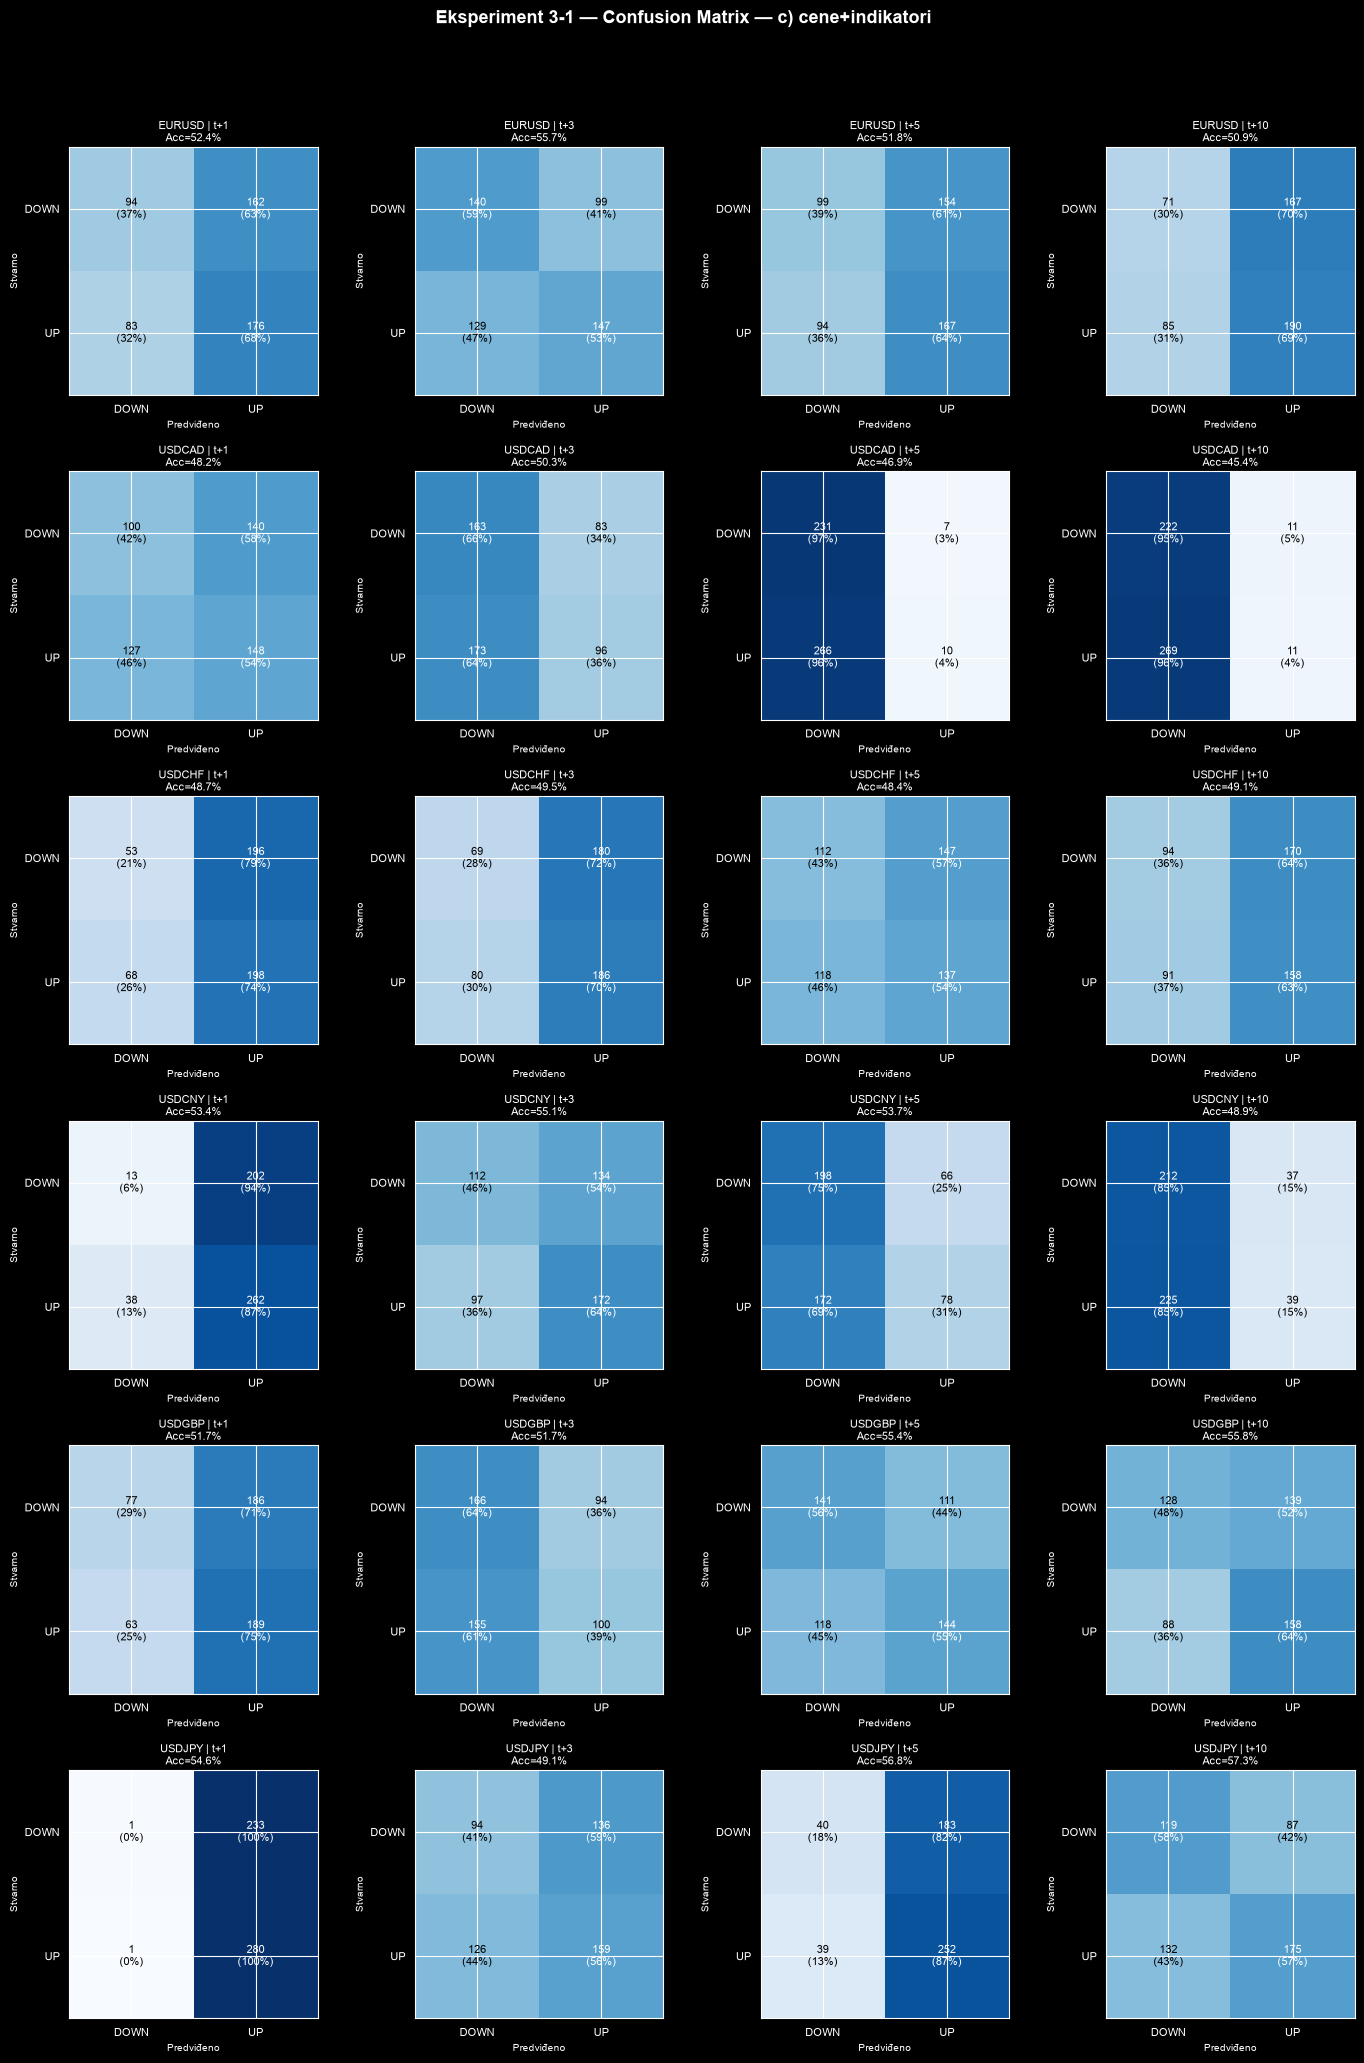

In [13]:

# Confusion matrix vizuelizacija — podslučaj c, po paru × horizontu
TARGET_SUB_3_1 = 'c) cene+indikatori'
pairs_3_1    = sorted({k[0] for k in predictions_3_1 if k[1] == TARGET_SUB_3_1})
horizons_3_1 = sorted({k[2] for k in predictions_3_1 if k[1] == TARGET_SUB_3_1})

if pairs_3_1 and horizons_3_1:
    fig, axes = plt.subplots(len(pairs_3_1), len(horizons_3_1),
                              figsize=(3.5 * len(horizons_3_1), 3.5 * len(pairs_3_1)),
                              squeeze=False)
    fig.suptitle(f"Eksperiment 3-1 — Confusion Matrix — {TARGET_SUB_3_1}", fontsize=13, fontweight='bold')
    for ri, pair in enumerate(pairs_3_1):
        for ci, h in enumerate(horizons_3_1):
            ax  = axes[ri][ci]
            key = (pair, TARGET_SUB_3_1, h)
            if key not in predictions_3_1:
                ax.set_visible(False)
                continue
            yt  = predictions_3_1[key]['y_test']
            yp  = predictions_3_1[key]['y_pred']
            acc = accuracy_score(yt, yp) * 100
            # binarizuj na DOWN(-1)=0 / UP(+1)=1 za cm prikaz
            yt_b = (yt > 0).astype(int)
            yp_b = (yp > 0).astype(int)
            cm   = confusion_matrix(yt_b, yp_b, labels=[0, 1])
            plot_confusion_matrix(cm, ax, f"{pair} | t+{h}\nAcc={acc:.1f}%")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

In [14]:

results_3_2     = []
predictions_3_2 = {}

for pair_name in features['Pair'].unique():
    pdf = features[features['Pair'] == pair_name].sort_values('Date').reset_index(drop=True)

    # --- Feature blokovi ---
    price_lags = pd.DataFrame(index=pdf.index)
    for lag in range(1, N_LAGS + 1):
        price_lags[f'Price_lag{lag}'] = pdf['Price'].shift(lag)
    roc_price = add_roc(pdf, ['Price'], ROC_WINDOW)

    indicator_lags = pd.DataFrame(index=pdf.index)
    for col in INDICATOR_COLS:
        indicator_lags[col] = pdf[col]
        for lag in range(1, N_LAGS_INDICATORS + 1):
            indicator_lags[f'{col}_lag{lag}'] = pdf[col].shift(lag)
    roc_indicators = add_roc(pdf, INDICATOR_COLS, ROC_WINDOW)

    targets = add_sign_roc_targets(pdf, HORIZONS_3)

    feature_sets = {
        'a) cene+ROC(cena)':      (pd.concat([price_lags, roc_price], axis=1),                                   'standard'),
        'b) ind+ROC(ind)':        (pd.concat([indicator_lags, roc_indicators], axis=1),                          'robust'),
        'c) cene+ind+ROC(oba)':   (pd.concat([price_lags, roc_price, indicator_lags, roc_indicators], axis=1),   'robust'),
    }

    for subcase, (X_df, scaler_type) in feature_sets.items():
        for h in HORIZONS_3:
            target_col = f"SignROC_{h}"
            combo = pd.concat([X_df, targets[[target_col]], pdf[['Date']]], axis=1).dropna()
            if len(combo) < 50:
                continue

            X         = combo[X_df.columns].values
            y         = combo[target_col].values
            dates_arr = combo['Date'].values

            metrics = run_classification(X, y, dates=dates_arr, scaler_type=scaler_type)
            if metrics is None:
                continue

            conv_flag = "✓konv." if metrics['converged'] else "⚠NIJE konvergirao"
            print(f"[3-2 {subcase} | {pair_name} | t+{h}]  "
                  f"Acc={metrics['Accuracy']:.1f}%  F1={metrics['F1']:.1f}%  "
                  f"feat={metrics['n_features']}  iter={metrics['n_iter']}  {conv_flag}")

            results_3_2.append({
                'Experiment': '3-2', 'Subcase': subcase, 'Pair': pair_name,
                'Horizon': f't+{h}',
                'Accuracy_%': round(metrics['Accuracy'], 1),
                'Precision_%': round(metrics['Precision'], 1),
                'Recall_%': round(metrics['Recall'], 1),
                'F1_%': round(metrics['F1'], 1),
                'Train_Size': metrics['Train_Size'], 'Test_Size': metrics['Test_Size'],
                'N_Features': metrics['n_features'], 'N_Iter': metrics['n_iter'],
                'Converged': metrics['converged'],
            })

            predictions_3_2[(pair_name, subcase, h)] = {
                'dates':  metrics['test_dates'],
                'y_test': metrics['y_test'],
                'y_pred': metrics['y_pred'],
            }

print("\n✓ Eksperiment 3-2 završen.")

[3-2 c) cene+ind+ROC(oba) | USDJPY | t+10]  Acc=63.3%  F1=62.9%  feat=58  iter=148  ✓konv.

✓ Eksperiment 3-2 završen.


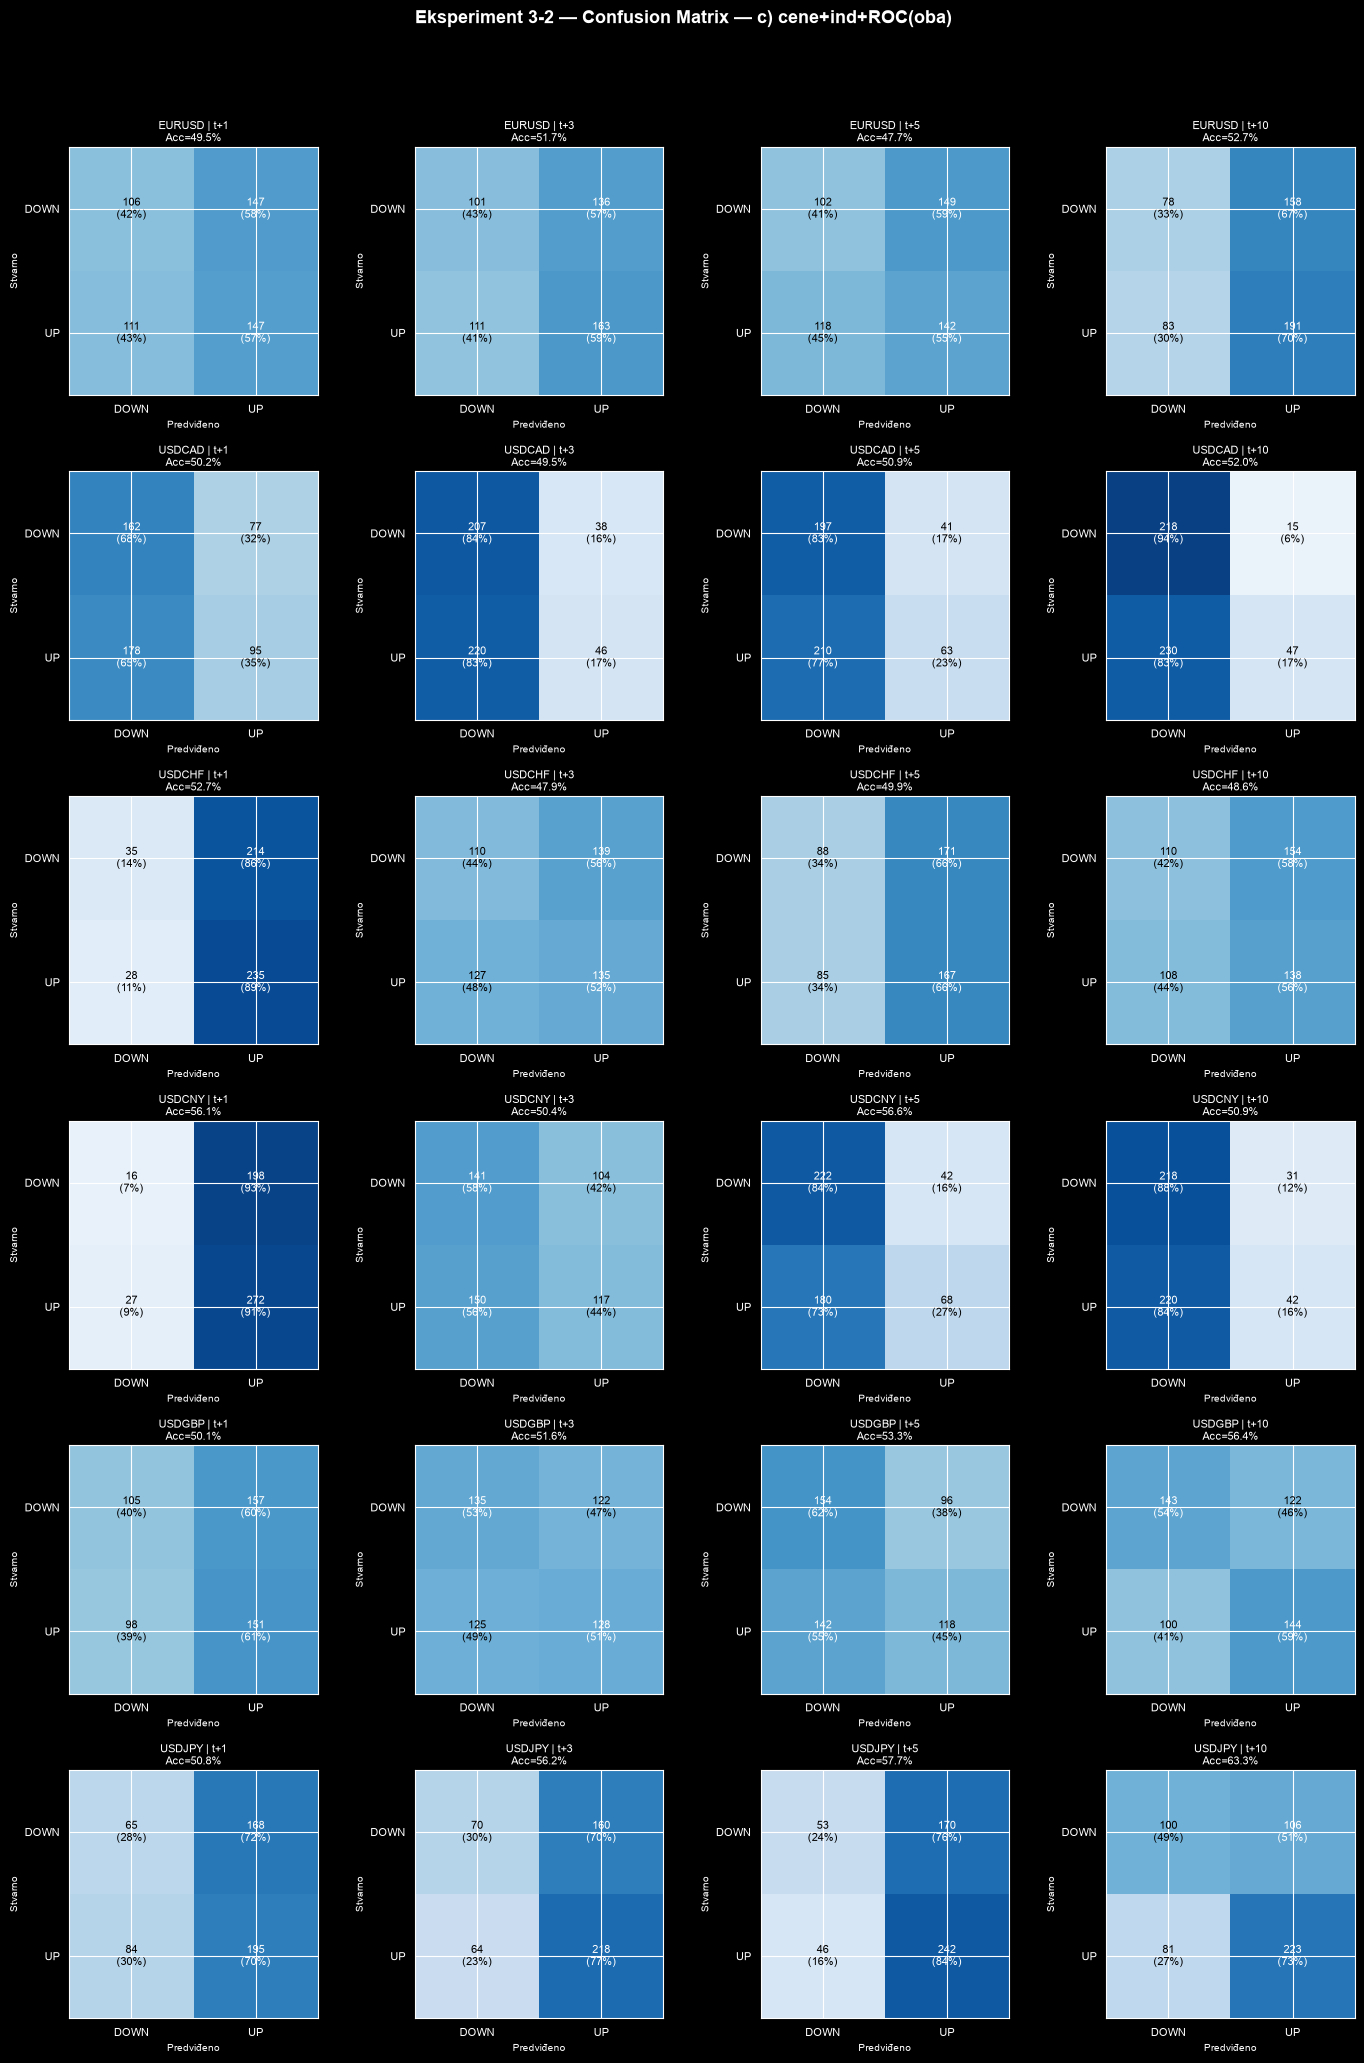

In [15]:

TARGET_SUB_3_2 = 'c) cene+ind+ROC(oba)'
pairs_3_2    = sorted({k[0] for k in predictions_3_2 if k[1] == TARGET_SUB_3_2})
horizons_3_2 = sorted({k[2] for k in predictions_3_2 if k[1] == TARGET_SUB_3_2})

if pairs_3_2 and horizons_3_2:
    fig, axes = plt.subplots(len(pairs_3_2), len(horizons_3_2),
                              figsize=(3.5 * len(horizons_3_2), 3.5 * len(pairs_3_2)),
                              squeeze=False)
    fig.suptitle(f"Eksperiment 3-2 — Confusion Matrix — {TARGET_SUB_3_2}", fontsize=13, fontweight='bold')
    for ri, pair in enumerate(pairs_3_2):
        for ci, h in enumerate(horizons_3_2):
            ax  = axes[ri][ci]
            key = (pair, TARGET_SUB_3_2, h)
            if key not in predictions_3_2:
                ax.set_visible(False)
                continue
            yt  = predictions_3_2[key]['y_test']
            yp  = predictions_3_2[key]['y_pred']
            acc = accuracy_score(yt, yp) * 100
            yt_b = (yt > 0).astype(int)
            yp_b = (yp > 0).astype(int)
            cm   = confusion_matrix(yt_b, yp_b, labels=[0, 1])
            plot_confusion_matrix(cm, ax, f"{pair} | t+{h}\nAcc={acc:.1f}%")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

In [16]:

results_3_3     = []
predictions_3_3 = {}

for pair_name in features['Pair'].unique():
    pdf = features[features['Pair'] == pair_name].sort_values('Date').reset_index(drop=True)

    # --- Feature blokovi ---
    price_lags = pd.DataFrame(index=pdf.index)
    for lag in range(1, N_LAGS + 1):
        price_lags[f'Price_lag{lag}'] = pdf['Price'].shift(lag)
    roc_price = add_roc(pdf, ['Price'], ROC_WINDOW)
    sma_price = add_sma(pdf, ['Price'], SMA_WINDOW)

    indicator_lags = pd.DataFrame(index=pdf.index)
    for col in INDICATOR_COLS:
        indicator_lags[col] = pdf[col]
        for lag in range(1, N_LAGS_INDICATORS + 1):
            indicator_lags[f'{col}_lag{lag}'] = pdf[col].shift(lag)
    roc_indicators = add_roc(pdf, INDICATOR_COLS, ROC_WINDOW)
    sma_indicators = add_sma(pdf, INDICATOR_COLS, SMA_WINDOW)

    targets = add_roc_targets(pdf, HORIZONS_3)

    feature_sets = {
        'a) cene+ROC+SMA(cena)':    (pd.concat([price_lags, roc_price, sma_price], axis=1),                                                       'standard'),
        'b) ind+ROC+SMA(ind)':      (pd.concat([indicator_lags, roc_indicators, sma_indicators], axis=1),                                          'robust'),
        'c) sve kombinovano':        (pd.concat([price_lags, roc_price, sma_price, indicator_lags, roc_indicators, sma_indicators], axis=1),        'robust'),
    }

    for subcase, (X_df, scaler_type) in feature_sets.items():
        for h in HORIZONS_3:
            target_col = f"ROC_{h}"
            combo = pd.concat([X_df, targets[[target_col]], pdf[['Date']]], axis=1).dropna()
            if len(combo) < 50:
                continue

            X         = combo[X_df.columns].values
            y         = combo[target_col].values
            dates_arr = combo['Date'].values

            metrics = run_regression(X, y, dates=dates_arr, scaler_type=scaler_type)
            if metrics is None:
                continue

            conv_flag = "✓konv." if metrics['converged'] else "⚠NIJE konvergirao"
            print(f"[3-3 {subcase} | {pair_name} | t+{h}]  "
                  f"MAE={metrics['MAE']:.5f}  RMSE={metrics['RMSE']:.5f}  R2={metrics['R2']:.4f}  "
                  f"MAPE={metrics['MAPE']:.2f}%  feat={metrics['n_features']}  iter={metrics['n_iter']}  {conv_flag}")

            results_3_3.append({
                'Experiment': '3-3', 'Subcase': subcase, 'Pair': pair_name,
                'Horizon': f't+{h}',
                'MAE': metrics['MAE'], 'RMSE': metrics['RMSE'],
                'R2': metrics['R2'],   'MAPE': metrics['MAPE'],
                'Train_Size': metrics['Train_Size'], 'Test_Size': metrics['Test_Size'],
                'N_Features': metrics['n_features'], 'N_Iter': metrics['n_iter'],
                'Converged': metrics['converged'],
            })

            predictions_3_3[(pair_name, subcase, h)] = {
                'dates':  metrics['test_dates'],
                'y_test': metrics['y_test'],
                'y_pred': metrics['y_pred'],
            }

print("\n✓ Eksperiment 3-3 završen.")

[3-3 c) sve kombinovano | USDJPY | t+10]  MAE=1.76460  RMSE=2.30801  R2=-0.4870  MAPE=362.04%  feat=72  iter=127  ✓konv.

✓ Eksperiment 3-3 završen.


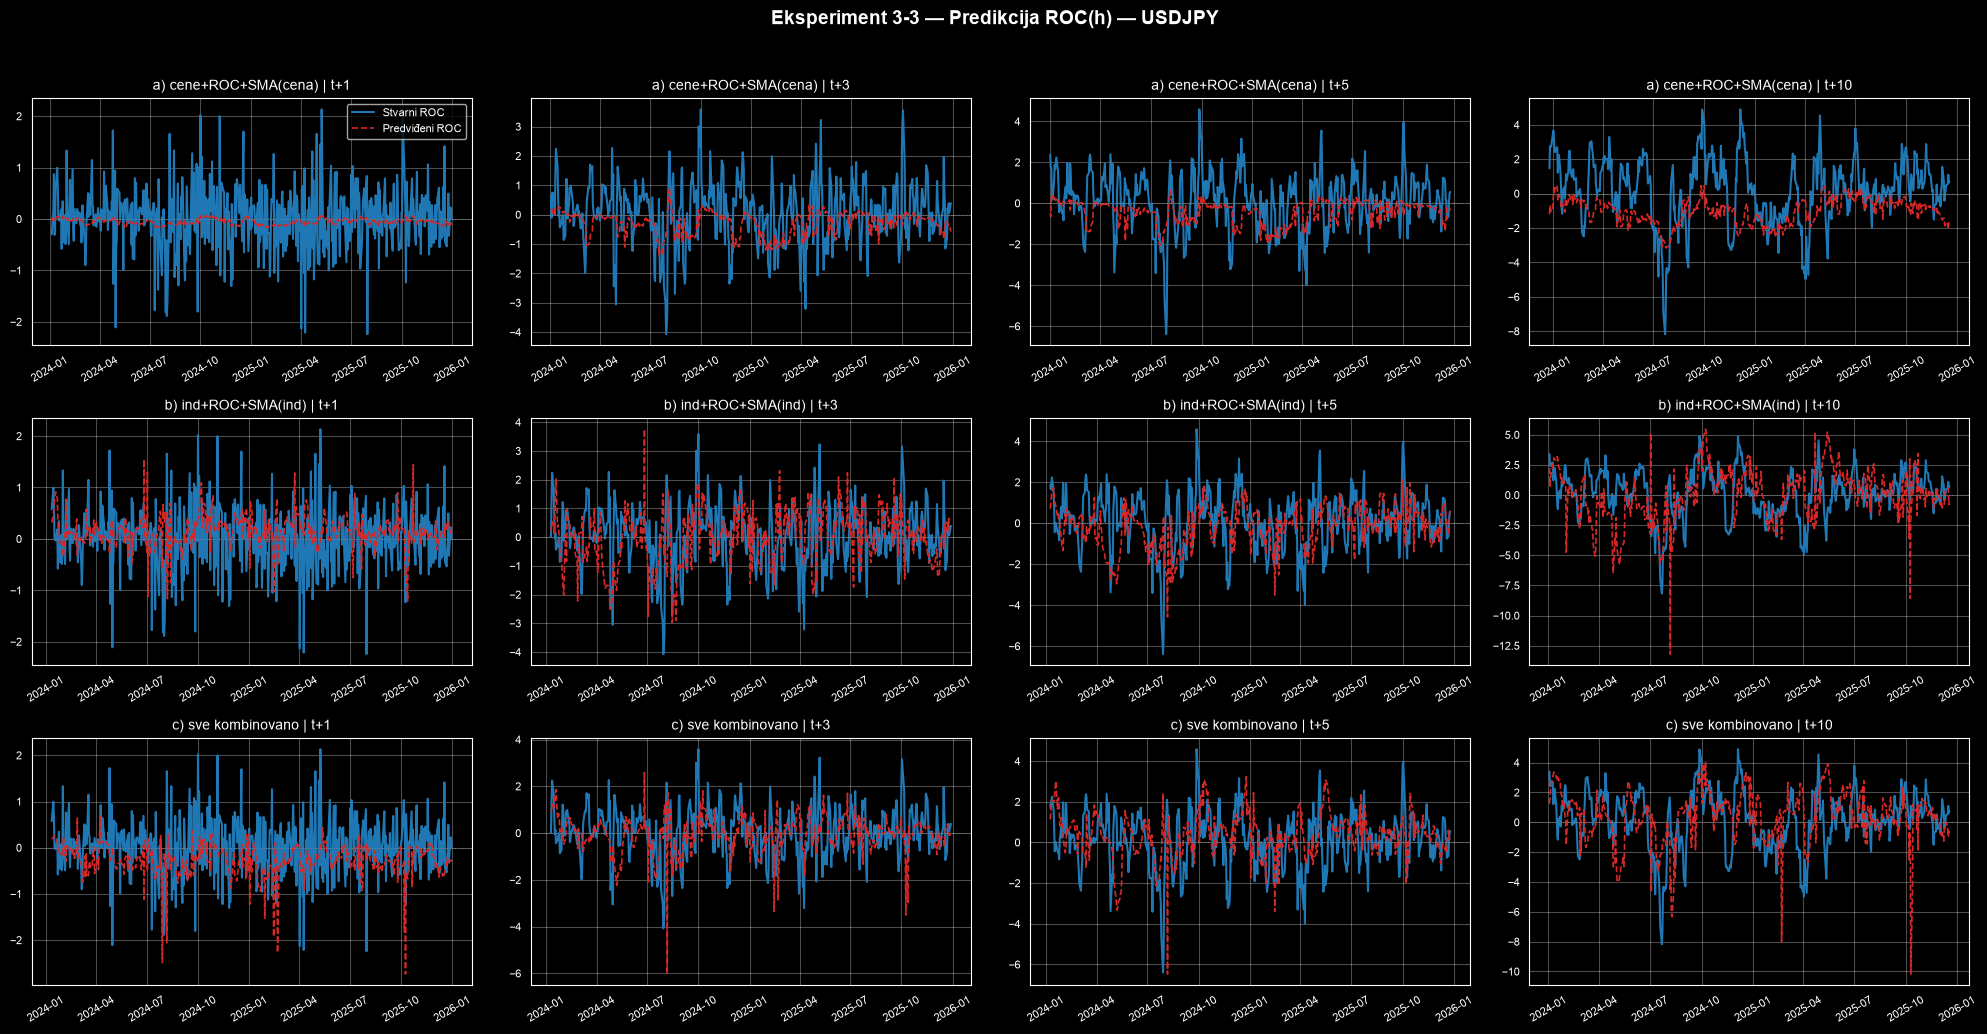

In [17]:

# Grafovi predikcije prinosa — podslučaj c, jedan par po paru
SUBCASES_3_3 = ['a) cene+ROC+SMA(cena)', 'b) ind+ROC+SMA(ind)', 'c) sve kombinovano']

for pair_name in features['Pair'].unique():
    fig, axes = plt.subplots(len(SUBCASES_3_3), len(HORIZONS_3),
                              figsize=(5 * len(HORIZONS_3), 3.5 * len(SUBCASES_3_3)),
                              squeeze=False)
    fig.suptitle(f"Eksperiment 3-3 — Predikcija ROC(h) — {pair_name}", fontsize=14, fontweight='bold')

    for row, subcase in enumerate(SUBCASES_3_3):
        for col, h in enumerate(HORIZONS_3):
            ax  = axes[row][col]
            key = (pair_name, subcase, h)
            if key not in predictions_3_3:
                ax.set_title(f"{subcase} | t+{h} (nema podataka)")
                ax.axis('off')
                continue
            data       = predictions_3_3[key]
            dates_plot = data['dates']
            y_test     = data['y_test']
            y_pred     = data['y_pred']

            ax.plot(dates_plot, y_test, label='Stvarni ROC', color='#1f77b4', linewidth=1.5)
            ax.plot(dates_plot, y_pred, label='Predviđeni ROC', color='#d62728', linewidth=1.2, linestyle='--')
            ax.axhline(0, color='gray', linewidth=0.7, linestyle=':')
            ax.set_title(f"{subcase} | t+{h}", fontsize=10)
            ax.xaxis.set_major_locator(mdates.AutoDateLocator())
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
            ax.tick_params(axis='x', rotation=30, labelsize=8)
            ax.tick_params(axis='y', labelsize=8)
            ax.grid(alpha=0.3)
            if row == 0 and col == 0:
                ax.legend(fontsize=8, loc='best')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

In [18]:

# --- 3-1 i 3-2 (klasifikacija) ---
clf_results = pd.DataFrame(results_3_1 + results_3_2)
clf_results  = clf_results[[
    'Experiment', 'Subcase', 'Pair', 'Horizon',
    'Accuracy_%', 'Precision_%', 'Recall_%', 'F1_%',
    'Train_Size', 'Test_Size', 'N_Features', 'N_Iter', 'Converged',
]]
print("\n--- Klasifikacija (3-1, 3-2) ---")
print(clf_results.to_string(index=False))

n_nc = (~clf_results['Converged']).sum()
if n_nc > 0:
    print(f"\n⚠ {n_nc} model(a) NIJE konvergiralo (max_iter={MLP_PARAMS_CLF['max_iter']})")

# --- 3-3 (regresija) ---
reg_results = pd.DataFrame(results_3_3)
reg_results  = reg_results[[
    'Experiment', 'Subcase', 'Pair', 'Horizon',
    'MAE', 'RMSE', 'R2', 'MAPE',
    'Train_Size', 'Test_Size', 'N_Features', 'N_Iter', 'Converged',
]]
print("\n--- Regresija (3-3) ---")
print(reg_results.to_string(index=False))

n_nc = (~reg_results['Converged']).sum()
if n_nc > 0:
    print(f"\n⚠ {n_nc} model(a) NIJE konvergiralo (max_iter={MLP_PARAMS_REG['max_iter']})")

# Excel export
clf_results.to_excel('Experiment3_Classification_Results.xlsx', index=False)
reg_results.to_excel('Experiment3_Regression_Results.xlsx',     index=False)



ZBIRNI REZULTATI — EKSPERIMENT 3 (3-1, 3-2, 3-3)

--- Klasifikacija (3-1, 3-2) ---
Experiment              Subcase   Pair Horizon  Accuracy_%  Precision_%  Recall_%  F1_%  Train_Size  Test_Size  N_Features  N_Iter  Converged
       3-1              a) cene EURUSD     t+1        50.1         49.8      50.1  44.0        2083        521           5      36       True
       3-1              a) cene EURUSD     t+3        52.4         52.6      52.4  52.5        2081        521           5      34       True
       3-1              a) cene EURUSD     t+5        50.8         50.5      50.8  46.3        2080        520           5      48       True
       3-1              a) cene EURUSD    t+10        54.1         53.7      54.1  53.4        2076        519           5      71       True
       3-1        b) indikatori EURUSD     t+1        50.9         50.9      50.9  48.0        2059        515          39      34       True
       3-1        b) indikatori EURUSD     t+3        52.8      